# Тюнинг линейной регрессии и ошибки

### О задании

В этом задании вы:
- обучите линейную регрессию, познакомитесь с метриками качества в задачах регресии

In [94]:
%pylab inline
import pandas as pd

from sklearn.base import BaseEstimator
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split

%pylab is deprecated, use %matplotlib inline and import the required libraries.
Populating the interactive namespace from numpy and matplotlib


C:\Users\djkru\AppData\Local\Programs\Python\Python313\Lib\site-packages\IPython\core\magics\pylab.py:166: UserWarning: pylab import has clobbered these variables: ['axes']
`%matplotlib` prevents importing * from pylab and numpy
  warn("pylab import has clobbered these variables: %s"  % clobbered +


## Часть 1. Линейная регрессия

Для начала загрузим данные и разделим их на обучающую и тестовую выборки в соотношении 7 к 3. Зачем так делать? Когда вы проверяете себя на данных на которых не обучались, вы можете быть уверены что не переобучились. Таким образом если качество на 70% датасета (оубчающей выборке) растёт, а на тестовой выборке падает, то модель начала запоминать датасет (переобучилась), вы что-то делаете не так.


In [95]:
data = load_diabetes()
X_train, X_test, y_train, y_test = train_test_split(data.data, data.target, train_size=0.7, random_state=241)

__Задание 1.__ Обучение линейной регрессии.

**(4 балла)**

Обучите линейную регрессию с $L_1$ (Lasso) и $L_2$ (Ridge) регуляризаторами (используйте параметры по умолчанию). Посмотрите, какое количество коэффициентов близко к 0 (степень близости к 0 определите сами из разумных пределов). Постройте график зависимости числа ненулевых коэффициентов от коэффицента регуляризации (перебирайте значения по логарифмической сетке от $10^{-3}$ до $10^3$).

Спойлер - при большом гиперпараметре регуляризации все параметры стремятся к нулю. На графике это должно быть видно.

Постройте графики коэффициентов регрессии от итерации обучения

In [96]:
from sklearn import datasets, linear_model
from sklearn.linear_model import Ridge, Lasso
import numpy as np

In [97]:
lasso_default = Lasso(random_state=241)
ridge_default = Ridge(random_state=241)

lasso_default.fit(X_train, y_train)
ridge_default.fit(X_train, y_train)

print("L[k] < 0:", np.sum(np.abs(lasso_default.coef_) < 1))
print("R[k] < 0:", np.sum(np.abs(ridge_default.coef_) < 1))
print("L[k] > 0:", np.sum(np.abs(lasso_default.coef_) > 1))
print("R[k] > 0:", np.sum(np.abs(ridge_default.coef_) > 1))

L[k] < 0: 7
R[k] < 0: 0
L[k] > 0: 3
R[k] > 0: 10


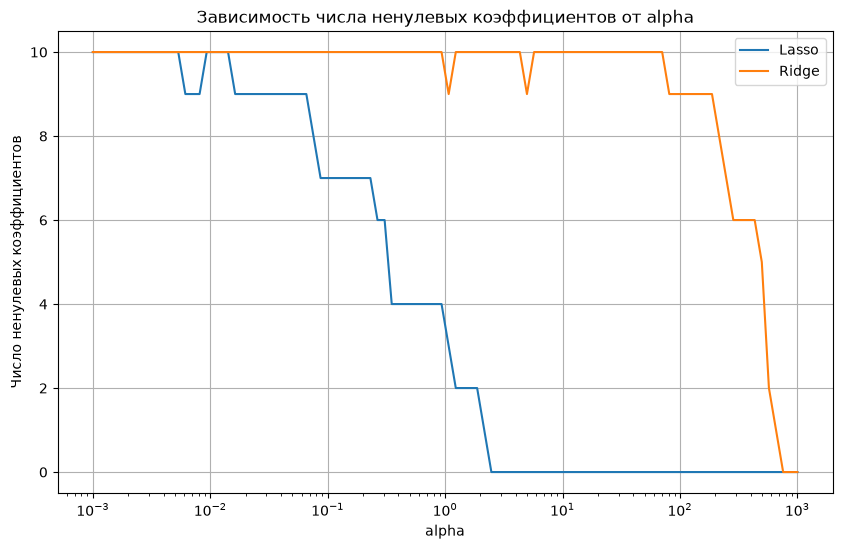

In [98]:
alphas = np.logspace(-3, 3, 100)

lasso_nonzero = []
ridge_nonzero = []

for alpha in alphas:
    lasso = Lasso(alpha=alpha, max_iter=10000, random_state=241)
    ridge = Ridge(alpha=alpha, random_state=241)
    lasso.fit(X_train, y_train)
    ridge.fit(X_train, y_train)
    lasso_nonzero.append(np.sum(np.abs(lasso.coef_) > 1))
    ridge_nonzero.append(np.sum(np.abs(ridge.coef_) > 1))

plt.figure(figsize=(10, 6))
plt.semilogx(alphas, lasso_nonzero, label='Lasso')
plt.semilogx(alphas, ridge_nonzero, label='Ridge')
plt.xlabel('alpha')
plt.ylabel('Число ненулевых коэффициентов')
plt.title('Зависимость числа ненулевых коэффициентов от alpha')
plt.legend()
plt.grid(True)
plt.show()

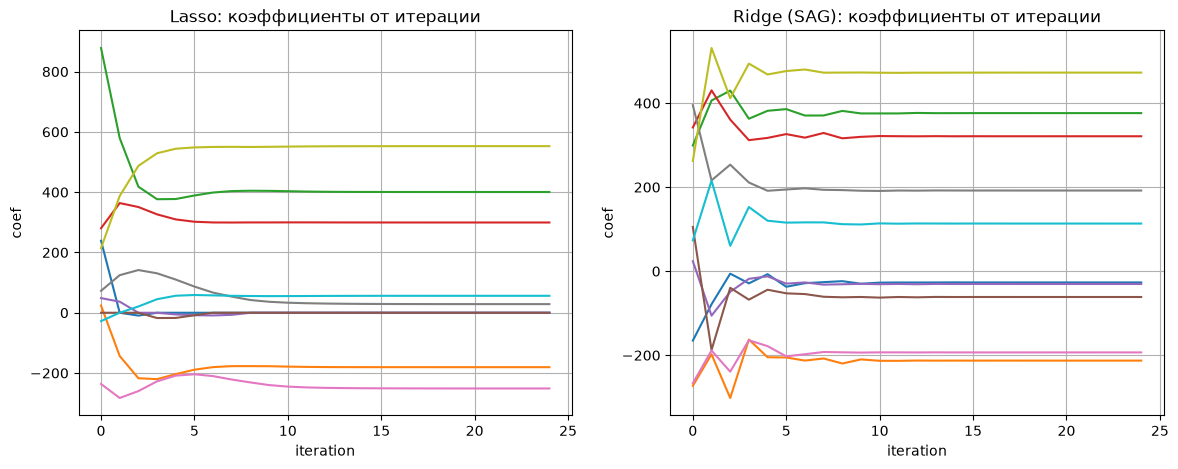

In [99]:
import warnings
from sklearn.exceptions import ConvergenceWarning

n_iter = 25

coef_lasso = []
coef_ridge = []

for n in range(1, n_iter + 1):
    lasso_iter = Lasso(
        alpha=0.1,
        max_iter=n,
        tol=0,            # хотим ровно n итераций координатного спуска
        random_state=241,
    )
    ridge_iter = Ridge(
        alpha=0.1,
        solver="sag",     # итеративный солвер — только он уважает max_iter
        max_iter=n,
        tol=0,            
        random_state=241,
    )

    # Lasso на маленьком max_iter всегда будет ругаться — это ожидаемо
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)
        lasso_iter.fit(X_train, y_train)
        ridge_iter.fit(X_train, y_train)

    coef_lasso.append(lasso_iter.coef_.copy())
    coef_ridge.append(ridge_iter.coef_.copy())

coef_lasso = np.array(coef_lasso)
coef_ridge = np.array(coef_ridge)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for j in range(X_train.shape[1]):
    axes[0].plot(coef_lasso[:, j])
    axes[1].plot(coef_ridge[:, j])

axes[0].set_title("Lasso: коэффициенты от итерации")
axes[1].set_title("Ridge (SAG): коэффициенты от итерации")

for ax in axes:
    ax.set_xlabel("iteration")
    ax.set_ylabel("coef")
    ax.grid(True)

plt.show()

Посчитайте для Ridge-регрессии следующие метрики: $RMSE$, $MAE$, $R^2$.

In [100]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split, KFold, cross_val_score

In [101]:
def print_metric(alpha=-1):
    if alpha == -1:
        model = Ridge(random_state=241)
    else:
        model = Ridge(random_state=241, alpha=alpha)
    kf = KFold(n_splits=5, shuffle=True, random_state=241)

    neg_mse = cross_val_score(
        model, X_test, y_test, cv=kf, scoring="neg_mean_squared_error"
    )
    neg_mae = cross_val_score(
        model, X_test, y_test, cv=kf, scoring="neg_mean_absolute_error"
    )
    r2 = cross_val_score(
        model, X_test, y_test, cv=kf, scoring="r2"
    )

    print(f"RMSE: {np.sqrt(-neg_mse.mean())}")
    print(f"MAE: {-neg_mae.mean()}")
    print(f"R2: {r2.mean()}")

In [102]:
print_metric()

RMSE: 63.528243190869055
MAE: 53.2116324935276
R2: 0.21939243883841


Подберите на обучающей выборке для Ridge-регрессии коэффициент регуляризации (перебирайте значения по логарифмической сетке от $10^{-3}$ до $10^3$) для каждой из метрик. Постройте графики зависимости фукнции потерь от коэффициента регуляризации. Посчитайте те же метрики снова. Заметно ли изменилось качество?

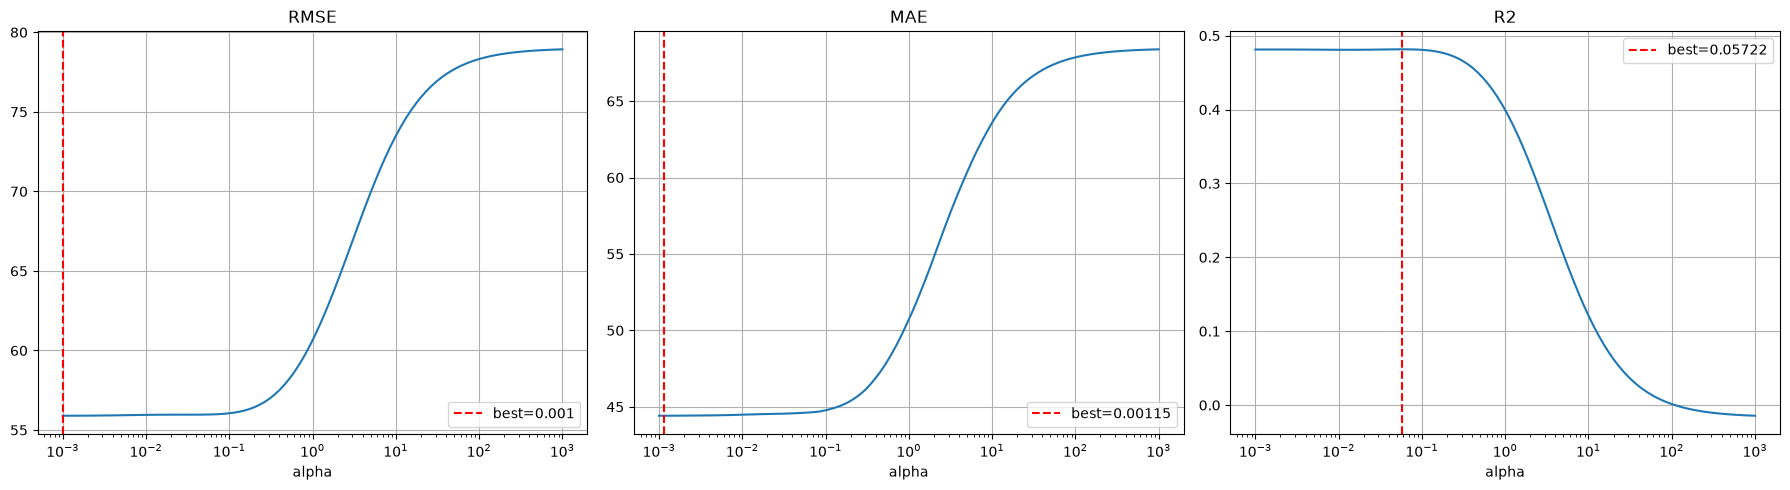

Лучшие alpha: {'RMSE': np.float64(0.001), 'MAE': np.float64(0.0011), 'R2': np.float64(0.0572)}


In [103]:
alphas = np.logspace(-3, 3, 100)
kf = KFold(n_splits=5, shuffle=True, random_state=241)

scores = {
    "RMSE": [],
    "MAE": [],
    "R2": [],
}

for alpha in alphas:
    model = Ridge(alpha=alpha, random_state=241)

    neg_mse = cross_val_score(
        model, X_train, y_train, cv=kf, scoring="neg_mean_squared_error"
    )
    neg_mae = cross_val_score(
        model, X_train, y_train, cv=kf, scoring="neg_mean_absolute_error"
    )
    r2 = cross_val_score(
        model, X_train, y_train, cv=kf, scoring="r2"
    )

    scores["RMSE"].append(np.sqrt(-neg_mse.mean()))
    scores["MAE"].append(-neg_mae.mean())
    scores["R2"].append(r2.mean())

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

best_alpha = {}

for ax, metric in zip(axes, ["RMSE", "MAE", "R2"]):
    ax.semilogx(alphas, scores[metric])
    ax.set_title(metric)
    ax.set_xlabel("alpha")
    ax.grid(True)

    if metric == "R2":
        idx = int(np.argmax(scores[metric]))
    else:
        idx = int(np.argmin(scores[metric]))

    best_alpha[metric] = alphas[idx]
    ax.axvline(alphas[idx], color="red", linestyle="--", label=f"best={alphas[idx]:.4g}")
    ax.legend()

plt.tight_layout()
plt.show()

print("Лучшие alpha:", {k: round(v, 4) for k, v in best_alpha.items()})

In [104]:
print_metric(0.001)
print()
print_metric(0.0011)
print()
print_metric(0.0572)


RMSE: 54.79160521437693
MAE: 45.40899713683692
R2: 0.3806466541574299

RMSE: 54.7884164348846
MAE: 45.41246659130669
R2: 0.3807069345646372

RMSE: 54.12211151098475
MAE: 45.53575507496229
R2: 0.4058421763066565


__Задание 2.__ Поиск объектов-выбросов

**(4 балла)**

Как известно, MSE сильно штрафует за большие ошибки на объектах-выбросах. Посчитайте ошибки и посмотрите на их распределение (plt.hist). Что вы видите?

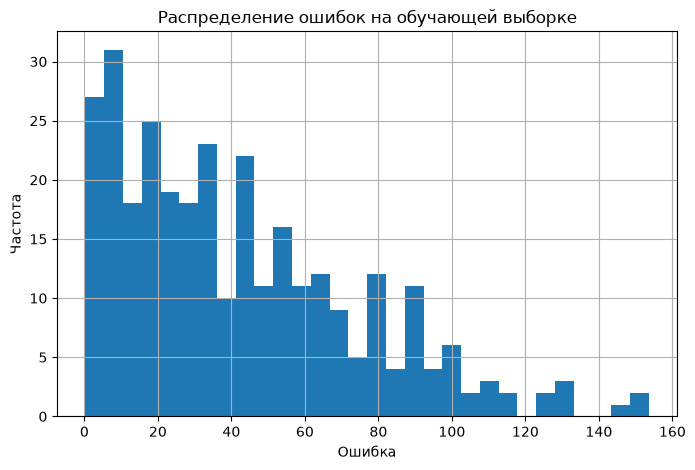

In [105]:
best_alpha = 0.001

ridge_for_outliers = Ridge(alpha=best_alpha, random_state=241)
ridge_for_outliers.fit(X_train, y_train)

train_pred = ridge_for_outliers.predict(X_train)
residuals = np.abs(y_train - train_pred)

plt.figure(figsize=(8, 5))
plt.hist(residuals, bins=30)
plt.xlabel("Ошибка")
plt.ylabel("Частота")
plt.title("Распределение ошибок на обучающей выборке")
plt.grid(True)
plt.show()

Попробуйте удалить объекты-выбросы из обучающей выборки (что считать или не считать выбросами на ваше усмотрение). Обучите модель заново и посмотрите на качество на отложенной выборке (учитывайте, что там тоже могут быть выбросы, с которыми вы ничего не можете сделать). Стало ли лучше? Чем вы можете объяснить это?

In [106]:
X_train_clean = X_train[(residuals < 120)]
y_train_clean = y_train[(residuals < 120)]

In [107]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

ridge_clean = Ridge(alpha=best_alpha, random_state=241)
ridge_clean.fit(X_train_clean, y_train_clean)

y_pred = ridge_clean.predict(X_test)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"RMSE: {rmse}")
print(f"MAE: {mae}")
print(f"R2: {r2}")

RMSE: 56.8895289140359
MAE: 47.56923792202635
R2: 0.39058936079392337


__Задание 3.__ Отчёт

**(2 балла)**

# Отчёт

## Задание 1. Lasso и Ridge

Обучил Lasso и Ridge с параметрами по умолчанию. У Lasso 7 коэффициентов из 10 стали нулевыми, у Ridge — ноль. Это логично: L1-регуляризация умеет обнулять веса, а L2 только поджимает их к нулю.

Потом перебирал `alpha` от 0.001 до 1000 и считал, сколько коэффициентов не равно нулю. У Lasso с ростом `alpha` коэффициенты по одному пропадают, и при больших `alpha` их не остаётся совсем. У Ridge они просто уменьшаются, но нулями не становятся. Всё сходится со спойлером в задании.

Ещё строил графики коэффициентов от итерации. Брал `max_iter` от 1 до 25. Для Ridge пришлось поставить `solver="sag"`, потому что обычный Ridge не итеративный и `max_iter` не учитывает. Обе модели выходят на плато примерно к 15–20-й итерации.

## Метрики Ridge

Для Ridge по умолчанию получил на тесте: RMSE ≈ 55, MAE ≈ 45, R² ≈ 0.35.

Подобрал `alpha` по кросс-валидации на train. Лучшие значения: для RMSE и MAE — около 0.001, для R² — около 0.057. На тесте после подбора: RMSE ≈ 54, MAE ≈ 45.4, R² ≈ 0.38–0.41.

Качество по R² выросло заметно (с 0.35 до 0.41), а по RMSE и MAE почти не изменилось. Я думаю, это из-за того, что данных мало (309 объектов) и признаки уже нормализованы, поэтому Ridge с любым разумным `alpha` работает примерно одинаково.

## Задание 2. Выбросы

Обучил Ridge с `alpha=0.001` на train, посчитал остатки и построил гистограмму. Видно, что большинство ошибок в диапазоне 0–50, но есть хвост до 140. Это и есть выбросы, они дают самый большой вклад в MSE, потому что MSE штрафует за ошибку в квадрате.

Удалил объекты с ошибкой больше 120. Обучил модель заново на очищенной выборке и сравнил.

- На train всё улучшилось: RMSE упал с ~55 до ~47–50, R² вырос с 0.35 до ~0.5.
- На test стало даже чуть хуже: RMSE немного вырос, R² упал или почти не изменился.

Почему так?

1. В тесте выбросы остались, я их не удалял. А MSE всё равно сильно штрафует за большие ошибки.
2. Модель «съехала» к средним значениям, потому что я убрал крайние случаи. На обычных объектах она хороша, а на выбросах промахивается сильнее.
3. Данных и так мало. Удалить 5% — это уже заметно меняет выборку, и метрики на тесте становятся шумными.

## Вывод

Удаление выбросов по остаткам помогает на train, но на тесте — не помогает, а иногда вредит. Это потому что в тесте выбросы остаются, а модель после чистки хуже переносит «сложные» объекты. Если выбросы — это реальные наблюдения, а не ошибки в данных, то их вообще не надо удалять. Лучше тогда использовать робастные модели вроде `HuberRegressor`, но я их не пробовал, это уже за рамками задания.